<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 07: Optics: transfer matrices, generation and outcoupling

**Goals.** Compute fields in thin-film stacks with the transfer-matrix method (TMM), turn them into
generation profiles under AM1.5G, and analyse OLED outcoupling with the dipole model.

### Theory
Each interface contributes $I_{jk}=\frac{1}{t_{jk}}\begin{pmatrix}1&r_{jk}\\r_{jk}&1\end{pmatrix}$ and each layer
$L_j=\mathrm{diag}(e^{-i\xi_jd_j},e^{i\xi_jd_j})$ with $\xi_j=2\pi\tilde n_j/\lambda$.
The absorbed photon flux density is $\propto \frac{4\pi n k}{\lambda}|E|^2$.
The dipole-emission model integrates the power spectrum $K(u)$ over in-plane wavevectors
$u=k_\parallel/k$ (CPS theory).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


bundled n,k data: ['Ag', 'Al', 'Au', 'BK7', 'ITO', 'P3HT-PCBM', 'PEDOT-PSS', 'SiO2']
mean G = 6.58e+27 m^-3 s^-1  ->  J_max = 105.3 A/m^2


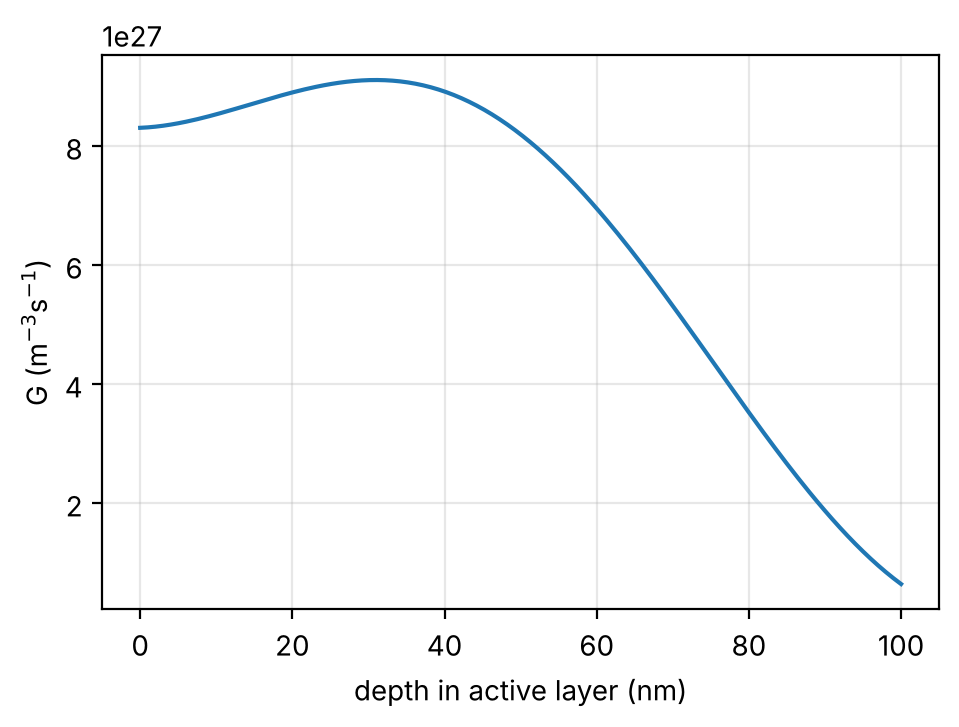

In [2]:
from orchid.optics import tmm_field, generation_profile, lorentz_nk
from orchid.materials import nk, am15g, available
print("bundled n,k data:", available())
stack = [("ITO", nk("ITO"), 120e-9), ("PEDOT:PSS", nk("PEDOT-PSS"), 40e-9),
         ("P3HT:PCBM", nk("P3HT-PCBM"), 100e-9), ("Al", nk("Al"), 100e-9)]
lams = np.linspace(350e-9, 800e-9, 46)
x, G, A = generation_profile(stack, 2, lams)
plt.plot(x * 1e9, G); plt.xlabel("depth in active layer (nm)"); plt.ylabel(r"G (m$^{-3}$s$^{-1}$)");
print(f"mean G = {G.mean():.2e} m^-3 s^-1  ->  J_max = {1.602e-19*G.mean()*100e-9:.1f} A/m^2")

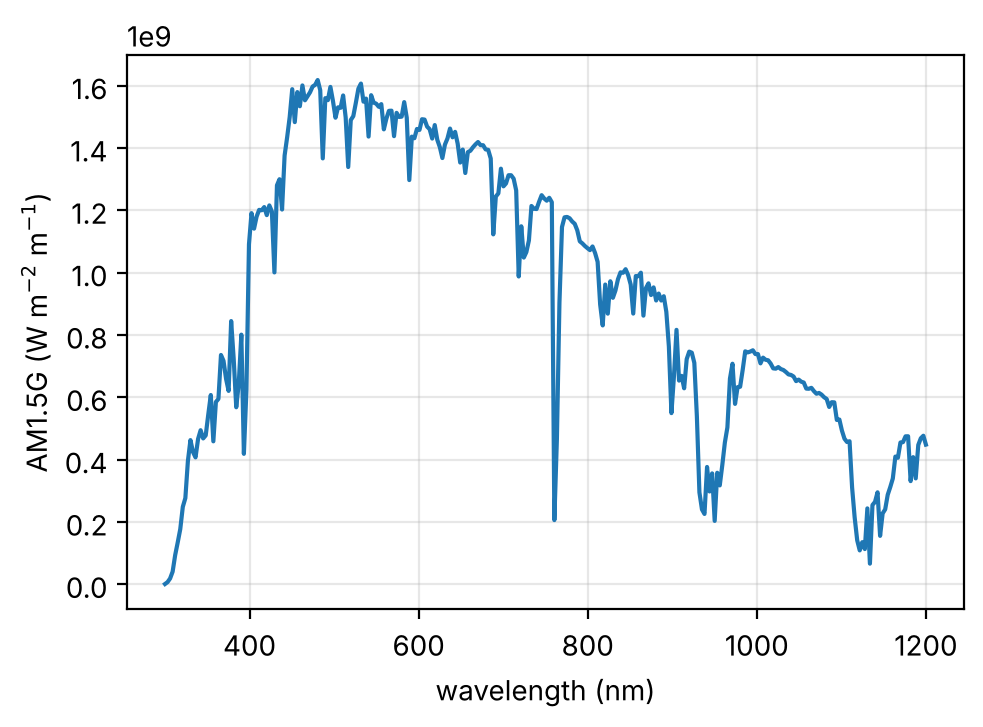

In [3]:
lam = np.linspace(300e-9, 1200e-9, 300)
plt.plot(lam * 1e9, am15g(lam)); plt.xlabel("wavelength (nm)"); plt.ylabel("AM1.5G (W m$^{-2}$ m$^{-1}$)");

### Dipole emission and outcoupling

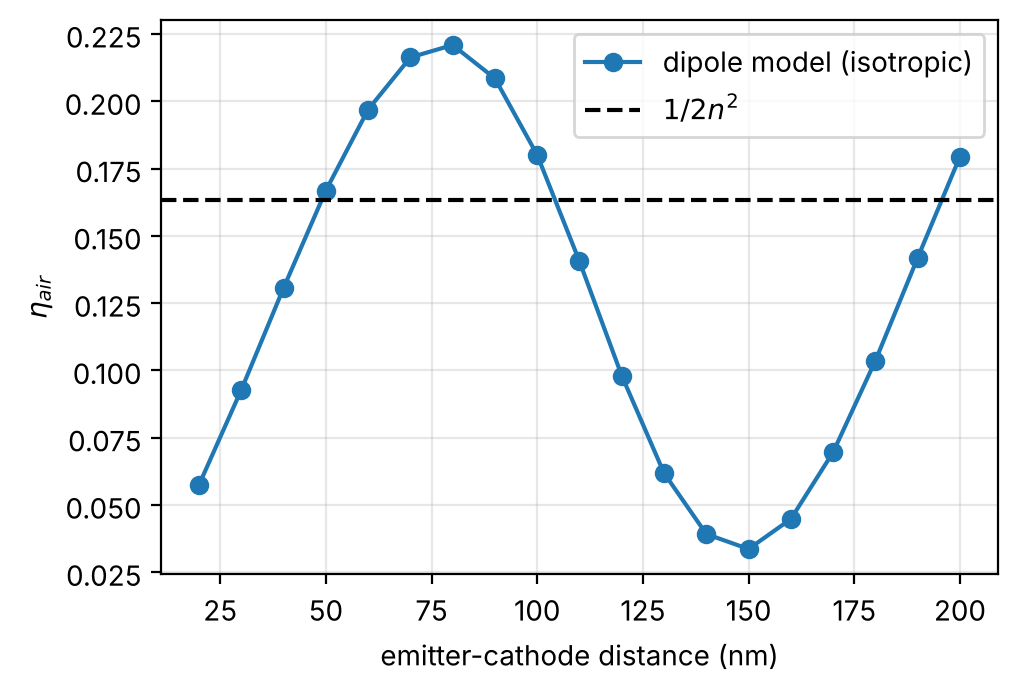

In [4]:
from orchid.optics import dipole_emission, outcoupling_classical
lam2 = 520e-9
etl = np.linspace(20e-9, 200e-9, 19)
eta = [dipole_emission(lam2, [(1.75, 30e-9), (nk("ITO")(lam2), 100e-9), (nk("BK7")(lam2).real, 0)],
                       (1.75, t), [(nk("Al")(lam2), 0)], 0.0, u_max=4, n_ev=8000)["eta_air"] for t in etl]
plt.plot(etl * 1e9, eta, "o-", label="dipole model (isotropic)")
plt.axhline(outcoupling_classical(1.75), c="k", ls="--", label=r"$1/2n^2$")
plt.xlabel("emitter-cathode distance (nm)"); plt.ylabel(r"$\eta_{air}$"); plt.legend();

**Exercise.** Change the emitter to horizontal dipoles (`theta=0`). Why does the outcoupling rise?

<details><summary>Solution</summary>

Horizontal dipoles emit mostly near the surface normal, inside the escape cone, and couple less to surface plasmons. That is why oriented emitters reach EQE above 30 %.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("07", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 07`.

In [5]:
from orchid.tutorials import quiz
quiz("07")

Quiz 07: Optics: transfer matrices, generation and outcoupling

Q1. The transfer-matrix method assumes
    (a) Coherent plane waves in planar layers, with interface and propagation matrices
    (b) Incoherent light
    (c) Geometric optics
    (d) Scattering by particles

Q2. The local absorption that sets the exciton generation rate is proportional to
    (a) |E|
    (b) n^2
    (c) n k |E|^2 (i.e. Im(eps) |E|^2)
    (d) R + T

Q3. For any lossless check of an optics solver, which identity must hold?
    (a) R + T = 2
    (b) A = 0 always
    (c) R + T + A = 1
    (d) R = T

Q4. The classical ray-optics estimate of OLED outcoupling into air is
    (a) n^2
    (b) 1/n
    (c) 1/(2 n^2)
    (d) 0.5

Q5. Near a metal mirror, a dipole's decay rate oscillates with distance and is strongly enhanced at very short distances. Why?
    (a) Exciton diffusion
    (b) Interference with its reflected field (CPS); near-field coupling to surface plasmons and lossy waves
    (c) Thermal effects
    (d

In [6]:
# replace with your answers, e.g. "abcda"
# quiz("07", answers=".....")

<details><summary>Answer key</summary>

`acccb`. Run `quiz("07", answers="acccb")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`